# Simple OLS regression


In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from IPython.display import display, Markdown, HTML

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'PROJECT_HANDOFF.txt').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from tools.scientific_plot_style import (
    BLUE, RED, apply_scientific_style, presentation_region_colors, clean_axis, r2_label)

ALPHA = .05
RESPONSES = {'accumulation': 'P_total_mm', 'intensity': 'P_exposed_mm_day'}
PREDICTORS = {'IVT': ('mean_IVT', 100.), 'Duration': ('detected_hours', 24.)}
SOURCE_HASHES = {'outputs/analysis_runs/19800101_20250101/05_ivt_152b8bbb2c607297/tables/event_region_local.parquet': 'e2bf047af1d24e633a8a790fba6a75312d4b2b7e7fd61f80de721242a304aa6b', 'outputs/analysis_runs/19800101_20250101/05_ivt_152b8bbb2c607297/tables/associations.parquet': 'ad2268de76edeba312be492b71e1692f0ce7832d8a02b72410223976a3c43310'}

In [2]:
def checked_table(name, columns):
    filename = next(p for p in SOURCE_HASHES if p.endswith('/'+name+'.parquet'))
    path = ROOT/filename
    assert hashlib.sha256(path.read_bytes()).hexdigest() == SOURCE_HASHES[filename], filename
    return pd.read_parquet(path, columns=columns)

observations = checked_table('event_region_local', [
    'track_id', 'region', 'first_detection', 'first_day_end', 'analysis_eligible',
    'mean_IVT', 'detected_hours', 'P_total_mm', 'P_exposed_mm_day'])
baseline = checked_table('associations', [
    'region', 'outcome', 'predictor', 'n', 'status', 'intercept', 'slope', 'R2'])
regions = list(dict.fromkeys(baseline.region))
region_colors = presentation_region_colors(regions, ROOT)
assert len(regions) == 17 and regions[0] == 'Full ROI'
assert len(observations) == 31999 and observations.analysis_eligible.all()
assert not observations.duplicated(['region', 'track_id']).any()
assert np.isfinite(observations[list(RESPONSES.values()) +
                              [p for p, _ in PREDICTORS.values()]]).all().all()
roi = observations[observations.region.eq('Full ROI')]
assert len(roi) == roi.track_id.nunique() == 6700
assert set(observations.track_id) == set(roi.track_id)
assert set(pd.to_datetime(roi.first_detection).dt.year) == set(range(1980, 2025))
apply_scientific_style()

In [3]:
models, summary_rows, coefficient_rows, audit_rows = {}, [], [], []
for region in regions:
    frame = observations[observations.region.eq(region)].sort_values(
        ['first_day_end', 'track_id']).reset_index(drop=True)
    for outcome, response in RESPONSES.items():
        y = frame[response].to_numpy(float)
        for label, (predictor, increment) in PREDICTORS.items():
            x = frame[predictor].to_numpy(float)
            X = sm.add_constant(x, has_constant='add')
            fit = sm.OLS(y, X, missing='raise').fit(cov_type='nonrobust', use_t=True)
            assert fit.df_resid == len(y)-2 and fit.cov_type == 'nonrobust'
            previous = baseline[baseline.region.eq(region) & baseline.outcome.eq(outcome)
                                & baseline.predictor.eq(predictor)].iloc[0]
            assert previous.status == 'ok' and len(y) == previous.n
            np.testing.assert_allclose(fit.params, [previous.intercept, previous.slope],
                                       rtol=1e-9, atol=1e-11)
            np.testing.assert_allclose(fit.rsquared, previous.R2, rtol=1e-10, atol=1e-12)
            key = {'region': region, 'outcome': outcome, 'model': label}
            summary_rows.append({**key, 'n': len(y), 'df_resid': int(fit.df_resid),
                'R2': fit.rsquared, 'adjusted_R2': fit.rsquared_adj,
                'residual_sd': np.sqrt(fit.mse_resid), 'residual_mean': fit.resid.mean(),
                'residual_skew': stats.skew(fit.resid),
                'negative_fitted': int(np.sum(fit.fittedvalues < 0)),
                'Pearson_r': stats.pearsonr(x, y).statistic})
            intervals = fit.conf_int(alpha=ALPHA)
            for j, term in enumerate(['Intercept', label]):
                scale = 1. if j == 0 else increment
                coefficient_rows.append({**key, 'term': term, 'increment': scale,
                    'beta': fit.params[j]*scale, 'OLS_SE': fit.bse[j]*scale,
                    'CI_low': intervals[j, 0]*scale, 'CI_high': intervals[j, 1]*scale,
                    't': fit.tvalues[j], 'p': fit.pvalues[j], 'df_resid': int(fit.df_resid)})
            audit_rows.append({**key, 'n': len(y),
                'intercept_difference': fit.params[0]-previous.intercept,
                'slope_difference_original_units': fit.params[1]-previous.slope,
                'R2_difference': fit.rsquared-previous.R2})
            models[(region, outcome, label)] = {'frame': frame, 'x': x, 'y': y, 'fit': fit}

simple_summary = pd.DataFrame(summary_rows)
simple_coefficients = pd.DataFrame(coefficient_rows)
invariance_audit = pd.DataFrame(audit_rows)
assert len(models) == 68 and len(simple_coefficients) == 136

## Full ROI


In [4]:
def p_text(value):
    return '<0.001' if value < .001 else f'{value:.3f}'

def show_table(frame, title=None):
    formats = {c: p_text if c == 'p' else '{:.4f}'
               for c in frame.select_dtypes(include='floating').columns}
    html = frame.to_html(index=False, border=0, formatters={
        k: v if callable(v) else v.format for k, v in formats.items()})
    if title:
        html = f'<details><summary><b>{title}</b></summary>{html}</details>'
    display(HTML(html))

slope_results = simple_coefficients[simple_coefficients.term.ne('Intercept')].merge(
    simple_summary[['region', 'outcome', 'model', 'n', 'R2']],
    on=['region', 'outcome', 'model'], validate='one_to_one')
result_columns = ['region', 'model', 'n', 'beta', 'OLS_SE', 'CI_low', 'CI_high', 'p', 'R2']
main_results = slope_results[slope_results.region.eq('Full ROI') &
                             slope_results.outcome.eq('accumulation')][result_columns]
labels = {'region': 'Area', 'model': 'Predictor', 'n': 'Events', 'beta': 'Slope',
          'OLS_SE': 'SE', 'CI_low': '95% CI lower', 'CI_high': '95% CI upper',
          'p': 'p', 'R2': 'R²'}
show_table(main_results.drop(columns='region').rename(columns=labels))

Predictor,Events,Slope,SE,95% CI lower,95% CI upper,p,R²
IVT,6700,0.3426,0.0117,0.3198,0.3655,<0.001,0.1142
Duration,6700,0.9373,0.0118,0.9141,0.9605,<0.001,0.4840


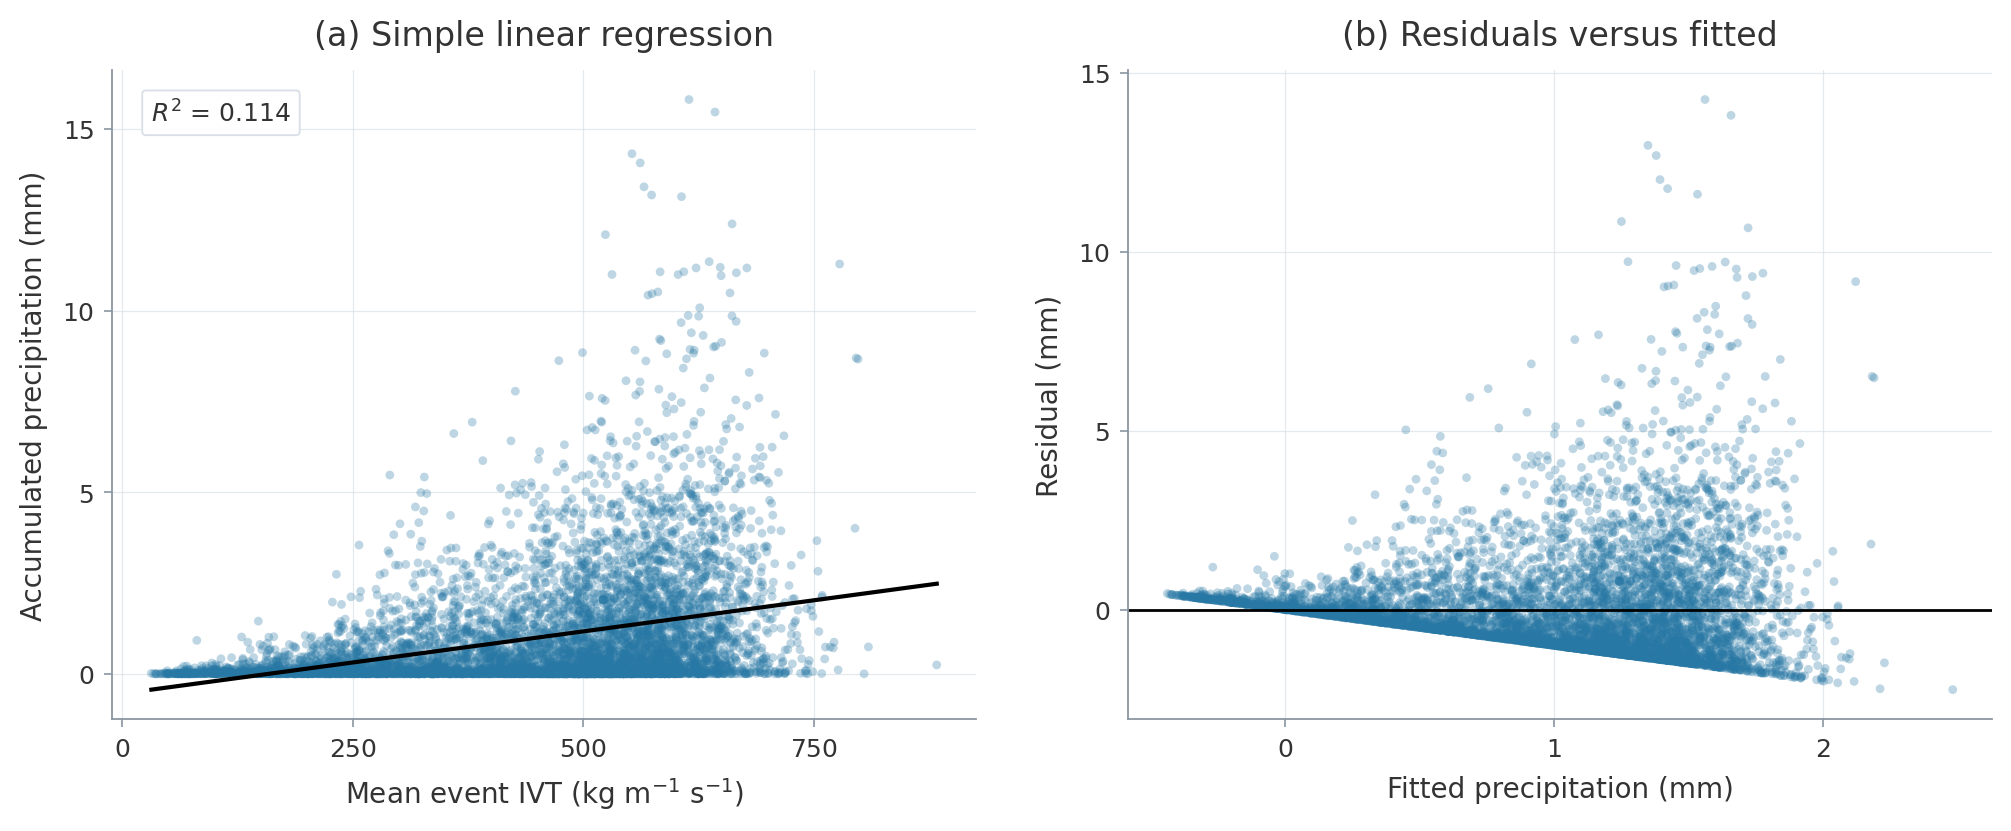

In [5]:
primary_model = models[('Full ROI', 'accumulation', 'IVT')]
x, y, fit = (primary_model[k] for k in ('x', 'y', 'fit'))
figure5, axes5 = plt.subplots(1, 2, figsize=(10, 4.1), layout='constrained')
axes5[0].scatter(x, y, s=10, alpha=.30, color=BLUE, edgecolors='none', rasterized=True)
grid = np.array([x.min(), x.max()])
axes5[0].plot(grid, fit.params[0]+fit.params[1]*grid, color='black', lw=1.5)
r2_label(axes5[0], fit.rsquared)
axes5[0].set(xlabel=r'Mean event IVT (kg m$^{-1}$ s$^{-1}$)',
             ylabel='Accumulated precipitation (mm)', title='(a) Simple linear regression')
axes5[1].scatter(fit.fittedvalues, fit.resid, s=10, alpha=.30, color=BLUE,
                 edgecolors='none', rasterized=True)
axes5[1].axhline(0, color='black', lw=1.)
axes5[1].set(xlabel='Fitted precipitation (mm)', ylabel='Residual (mm)',
             title='(b) Residuals versus fitted')
for axis in axes5:
    clean_axis(axis)
display(figure5)
plt.close(figure5)

## Regions


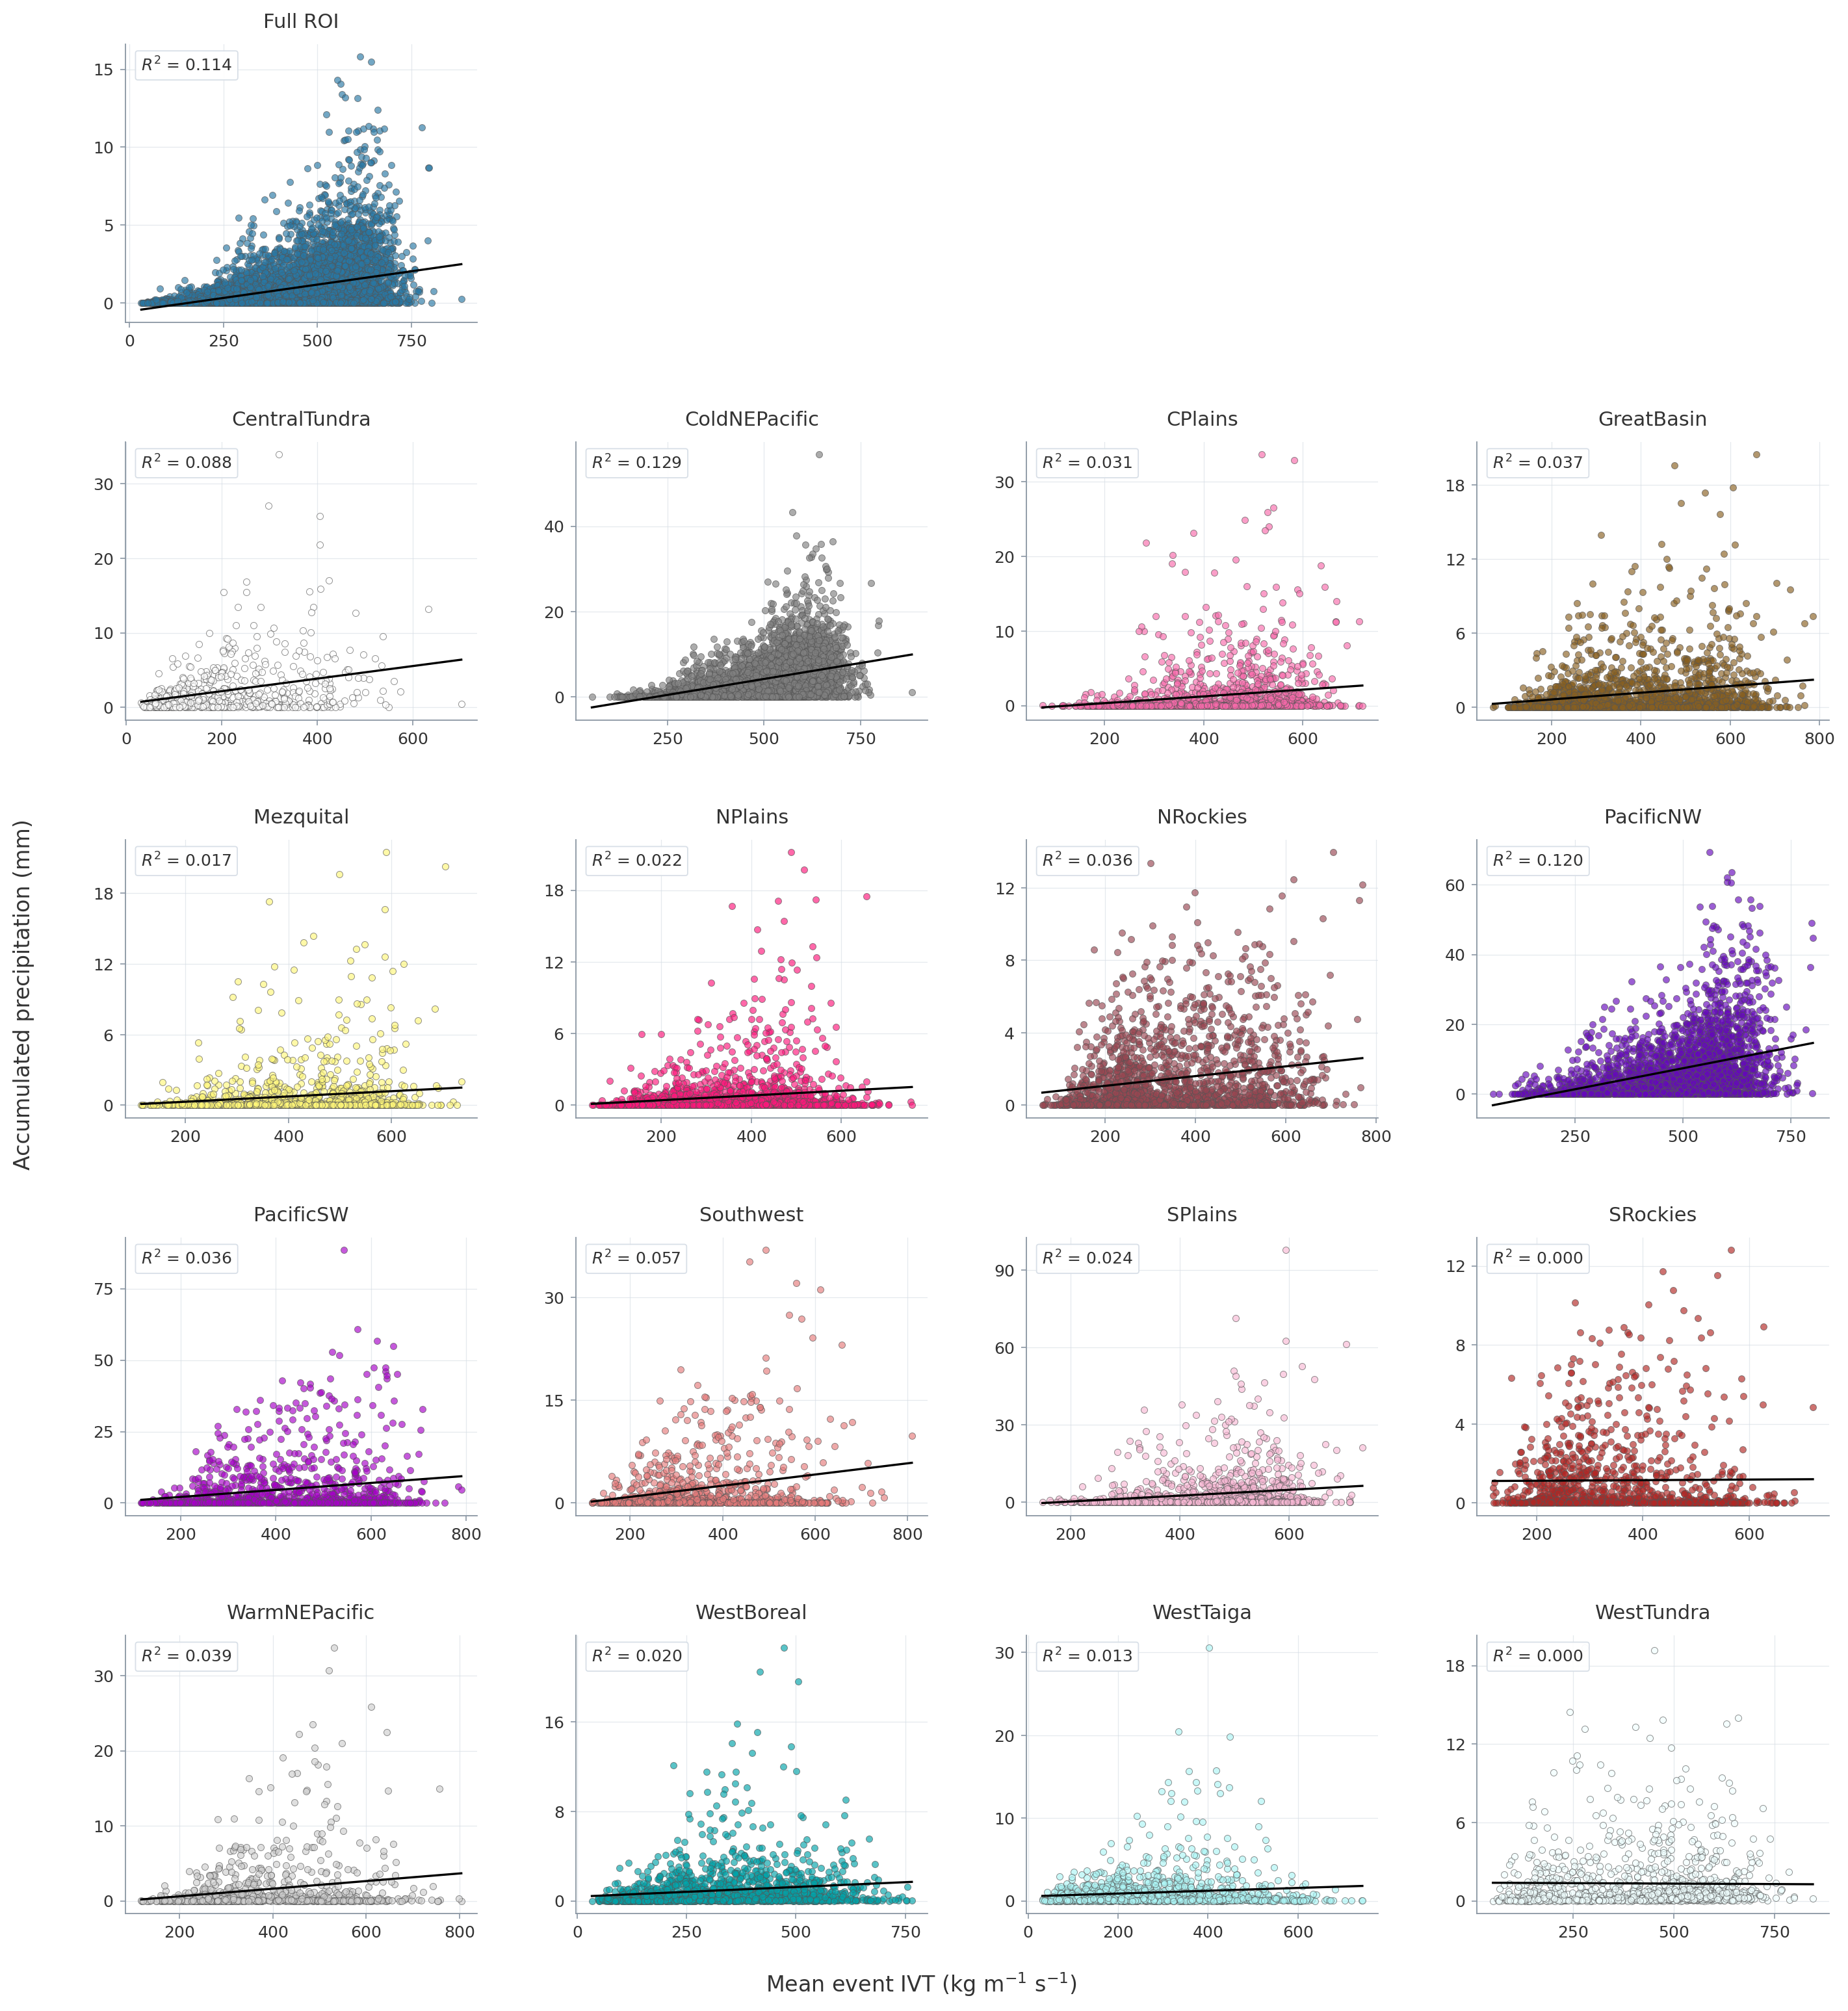

In [6]:
# Full ROI at upper left; unchanged 05 region order and colors in the 4×4 grid below.
regional_figure = plt.figure(figsize=(14.4, 16.25))
layout = regional_figure.add_gridspec(5, 4, left=.075, right=.985, top=.95,
                                    bottom=.065, hspace=.43, wspace=.28)
regional_axes = [regional_figure.add_subplot(layout[0, 0])]
regional_axes.extend(regional_figure.add_subplot(layout[r+1, c])
                     for r in range(4) for c in range(4))
for axis, region in zip(regional_axes, regions):
    model = models[(region, 'accumulation', 'IVT')]
    x, y, fit = (model[k] for k in ('x', 'y', 'fit'))
    axis.scatter(x, y, s=13, alpha=.65, color=region_colors[region],
                 edgecolors='#555555', linewidths=.35, rasterized=True)
    grid = np.array([x.min(), x.max()])
    axis.plot(grid, fit.params[0]+fit.params[1]*grid, color='black', lw=1.2)
    r2_label(axis, fit.rsquared)
    axis.set_title(region, fontsize=11)
    clean_axis(axis)
regional_figure.supxlabel('Mean event IVT (kg m$^{-1}$ s$^{-1}$)', y=.025)
regional_figure.supylabel('Accumulated precipitation (mm)', x=.015)
display(regional_figure)
plt.close(regional_figure)

In [7]:
regional_results = slope_results[
    slope_results.region.ne('Full ROI') & slope_results.outcome.eq('accumulation')][result_columns]
show_table(regional_results.rename(columns=labels), 'Regional coefficients and R²')

Area,Predictor,Events,Slope,SE,95% CI lower,95% CI upper,p,R²
CentralTundra,IVT,603,0.8432,0.1106,0.6260,1.0604,<0.001,0.0882
CentralTundra,Duration,603,2.6308,0.4194,1.8072,3.4544,<0.001,0.0615
ColdNEPacific,IVT,3869,1.4941,0.0625,1.3716,1.6166,<0.001,0.1288
ColdNEPacific,Duration,3869,2.5718,0.0488,2.4762,2.6674,<0.001,0.4183
CPlains,IVT,1506,0.4540,0.0652,0.3261,0.5819,<0.001,0.0312
CPlains,Duration,1506,2.5623,0.1387,2.2903,2.8344,<0.001,0.1849
GreatBasin,IVT,1779,0.2719,0.0331,0.2070,0.3368,<0.001,0.0366
GreatBasin,Duration,1779,2.3785,0.0803,2.2210,2.5359,<0.001,0.3307
Mezquital,IVT,1282,0.2236,0.0474,0.1307,0.3165,<0.001,0.0171
Mezquital,Duration,1282,1.7475,0.0984,1.5545,1.9405,<0.001,0.1978
